# Import necessary libraries:

In [21]:
# آرین عبداللهی 40023055
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, OneHotEncoder


# Load and Preprocess dataset

In [22]:
# Load the dataset using pandas.read_csv

df1 = pd.read_csv("C:\\Users\\Arian\\Desktop\\adult.csv")

In [23]:
# Print first rows the dataset
print(df1.iloc[:1]) 

   age workclass  fnlwgt education  educational-num marital-status  \
0   25   Private  226802      11th                7  Never-married   

          occupation relationship   race gender  capital-gain  capital-loss  \
0  Machine-op-inspct    Own-child  Black   Male             0             0   

   hours-per-week native-country income  
0              40  United-States  <=50K  


In [24]:
# Drop rows with any missing values
for i in df1.columns:
    df1 = df1.drop(df1[df1[i] == '?'].index) # drop any row from our dataset that contain "?" in columns  
m=df1.head(15)
df= df1.reset_index(drop=True)
df


,age,workclass,fnlwgt,education,educational-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country,income
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,34,Private,198693,10th,6,Never-married,Other-service,Not-in-family,White,Male,0,0,30,United-States,<=50K
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
45217,27,Private,257302,Assoc-acdm,12,Married-civ-spouse,Tech-support,Wife,White,Female,0,0,38,United-States,<=50K
45218,40,Private,154374,HS-grad,9,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,0,0,40,United-States,>50K
45219,58,Private,151910,HS-grad,9,Widowed,Adm-clerical,Unmarried,White,Female,0,0,40,United-States,<=50K
45220,22,Private,201490,HS-grad,9,Never-married,Adm-clerical,Own-child,White,Male,0,0,20,United-States,<=50K


# Visualize dataset

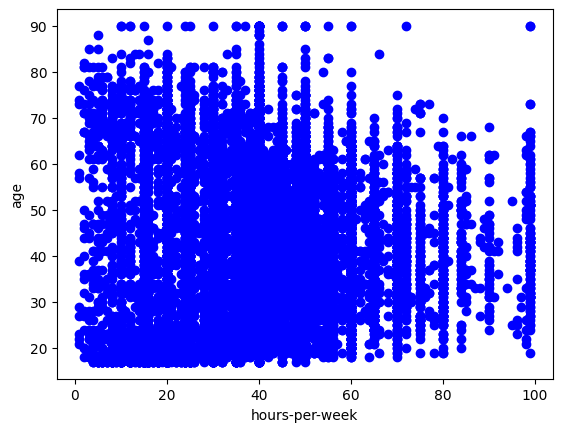

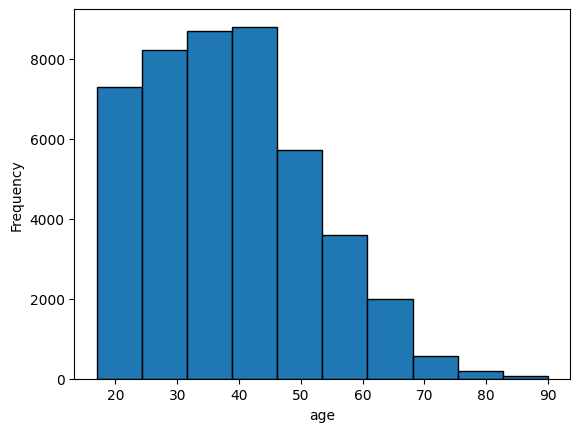

C:\Users\Arian\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\seaborn\axisgrid.py:123: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)


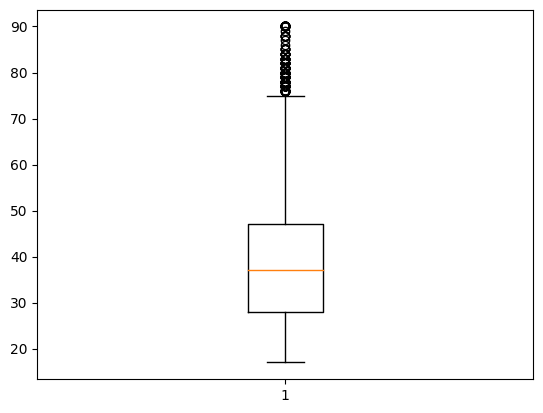

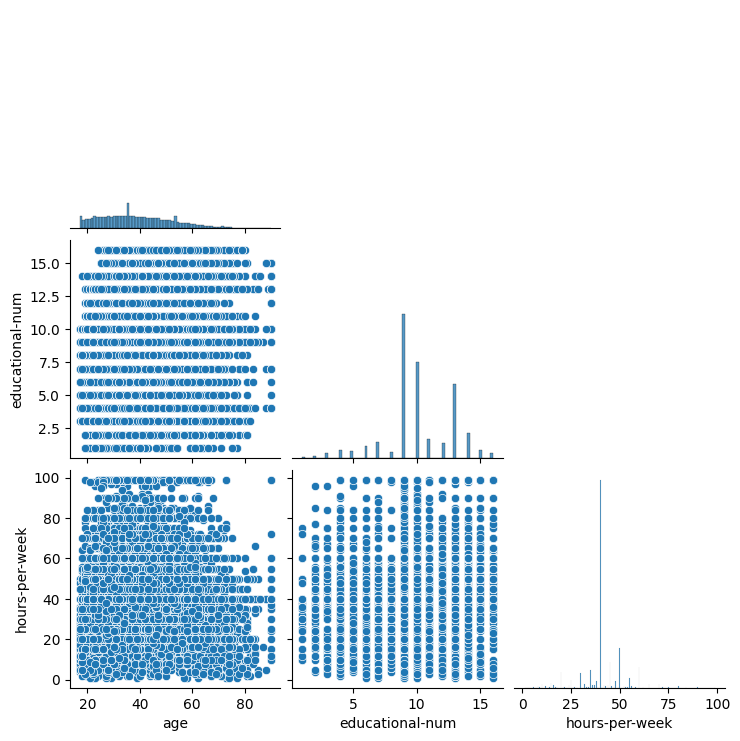

In [25]:
# Visualize the dataset using scatter plots, histograms, box plots, and pair plots to understand the data distribution, identify outliers, and detect patterns.


# Scatter plot for Age vs Hours-per-week

# your code here:



plt.show()
x=df["hours-per-week"]
y=df["age"]
plt.scatter(x,y,c='b')
plt.xlabel('hours-per-week')
plt.ylabel('age')


# Histogram for distribution of age distribution

# your code here:

plt.show()
plt.hist(y,bins=10,edgecolor='black')
plt.xlabel('age')
plt.ylabel('Frequency')

# # Box plot for age to see outliers

# # your code here:

q1 = np.quantile(y, .25)  # calculate quantile 1 
q2 = np.quantile(y, .5)   # calculate quantile 2
q3 = np.quantile(y, .75)  # calculate quantile 3
iqr = q3 - q1             # calculate iqr
# identify outliers
lv = q1 - 1.5 * iqr       
hv = q3 + 1.5 * iqr

plt.show()
plt=plt.boxplot(y)


# # Pair plot for Age, education-num, and hours-per-week

# # your code here:
g=sns.pairplot(
        df,
    x_vars=['age','educational-num','hours-per-week'],
    y_vars=['age','educational-num','hours-per-week'],
    corner=True,
    height=2.5,
    
    
)





# Encode and Normalize dataset

In [26]:
# Use one-hot endcoding to convert categorical features into numerical format

categorical_columns = df.select_dtypes(include=['object']).columns.tolist()

# This line selects all columns from the DataFrame 'df' that have the data type 'object' (typically strings).
# Then, it extracts the column names from the result (a pandas Index object) and converts them to a regular Python list using .tolist()

# 2. Create a One-Hot Encoder object
encoder = OneHotEncoder(sparse_output=False)

# 3. Apply One-Hot Encoding
one_hot_encoded = encoder.fit_transform(df[categorical_columns])

# This line fits the encoder to the data in the selected categorical columns from 'df'. It then transforms the data using one-hot encoding and stores the result in 'one_hot_encoded'.

# 4. Create a DataFrame from the encoded data
one_hot_df = pd.DataFrame(one_hot_encoded, columns=encoder.get_feature_names_out(categorical_columns))

# This line creates a new DataFrame 'one_hot_df' from the one-hot encoded data in 'one_hot_encoded'.
# The columns are named using the encoder's 'get_feature_names_out' method, which provides the names for the encoded features based on the original categorical column names and categories.

# 5. Combine original and encoded data
df_encoded = pd.concat([df, one_hot_df], axis=1)

# This line combines the original DataFrame 'df' with the one-hot encoded DataFrame 'one_hot_df' by concatenating them along axis=1 (columns).

# 6. Drop original categorical columns
df_encoded = df_encoded.drop(categorical_columns, axis=1)

# This line drops the original categorical columns (those selected in step 1) from the combined DataFrame 'df_encoded'. This is done because the information is now encoded in the new one-hot encoded columns.

df_encoded



,age,fnlwgt,educational-num,capital-gain,capital-loss,hours-per-week,workclass_Federal-gov,workclass_Local-gov,workclass_Private,workclass_Self-emp-inc,...,native-country_Scotland,native-country_South,native-country_Taiwan,native-country_Thailand,native-country_Trinadad&Tobago,native-country_United-States,native-country_Vietnam,native-country_Yugoslavia,income_<=50K,income_>50K
0,25,226802,7,0,0,40,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
1,38,89814,9,0,0,50,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
2,28,336951,12,0,0,40,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
3,44,160323,10,7688,0,40,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
4,34,198693,6,0,0,30,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
45217,27,257302,12,0,0,38,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
45218,40,154374,9,0,0,40,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
45219,58,151910,9,0,0,40,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
45220,22,201490,9,0,0,20,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0


In [27]:
# Use StandardScaler from sklearn.preprocessing to normalize the features.

scaler = StandardScaler()

# your code here:
pca_imp=scaler.fit_transform(df_encoded) 
pca_imp

array([[-1.02498291,  0.35088942, -1.22155881, ..., -0.02255794,
         0.57403082, -0.57403082],
       [-0.04145504, -0.94587846, -0.43812161, ..., -0.02255794,
         0.57403082, -0.57403082],
       [-0.79801494,  1.39359159,  0.73703421, ..., -0.02255794,
        -1.74206675,  1.74206675],
       ...,
       [ 1.47166476, -0.35805983, -0.43812161, ..., -0.02255794,
         0.57403082, -0.57403082],
       [-1.25195088,  0.11127873, -0.43812161, ..., -0.02255794,
         0.57403082, -0.57403082],
       [ 1.01772882,  0.92951628, -0.43812161, ..., -0.02255794,
        -1.74206675,  1.74206675]])

# Implement PCA from Scratch

In [28]:
# Start by ensuring all data is numeric and normalized.
# Subtract the mean to center the data, calculate the covariance matrix, find eigenvalues and eigenvectors, sort them, and project the data onto the principal components.
# This section will test your understanding of PCA's mathematical foundation.


# your code here:

mean_vec = np.mean(pca_imp, axis=0)
cov_mat = (pca_imp - mean_vec).T.dot((pca_imp - mean_vec)) / (pca_imp.shape[0]-1) # calculte covariance matrix with formula 
print('Covariance matrix \n%s' %cov_mat)

cov_matrix = np.cov(pca_imp.T)        # calculte covariance matrix with numpy functions
eigen_values, eigen_vectors = np.linalg.eig(cov_matrix)

# sort eigen values and eigen vectors
sorted_index = np.argsort(eigen_values)[::-1] 
sorted_eigenvalue = eigen_values[sorted_index]
sorted_eigenvectors = eigen_vectors[:,sorted_index]

# choose 10 principal components
k=10
principal_components = sorted_eigenvectors[:,:k]
pca_imp_new = np.dot(pca_imp, principal_components)
pca_imp_new


Covariance matrix 
[[ 1.00002211 -0.07579365  0.03762378 ...  0.00329444 -0.23704548
   0.23704548]
 [-0.07579365  1.00002211 -0.04199395 ...  0.00486733  0.00726407
  -0.00726407]
 [ 0.03762378 -0.04199395  1.00002211 ... -0.00642556 -0.33280724
   0.33280724]
 ...
 [ 0.00329444  0.00486733 -0.00642556 ...  1.00002211 -0.00522382
   0.00522382]
 [-0.23704548  0.00726407 -0.33280724 ... -0.00522382  1.00002211
  -1.00002211]
 [ 0.23704548 -0.00726407  0.33280724 ...  0.00522382 -1.00002211
   1.00002211]]


array([[-2.70205967,  2.07100727, -0.18258601, ..., -2.18042798,
         0.85911597, -1.55115431],
       [ 1.35560654,  2.2726329 ,  0.83794462, ...,  1.31411923,
         0.43913136, -0.73004302],
       [ 3.1460791 , -0.85655569,  0.23181742, ..., -1.3029862 ,
        -0.82968656,  3.78023493],
       ...,
       [-2.37475945, -1.05236365, -0.31680012, ...,  1.31287614,
         0.75785266, -0.10404178],
       [-2.29966078,  0.91635003,  1.6157164 , ...,  0.81227804,
         0.55309883,  0.77953603],
       [ 2.06008046, -2.14295803, -0.59360251, ...,  0.9288997 ,
        -0.31582328, -2.37243084]])

# Visualize the PCA-reduced data

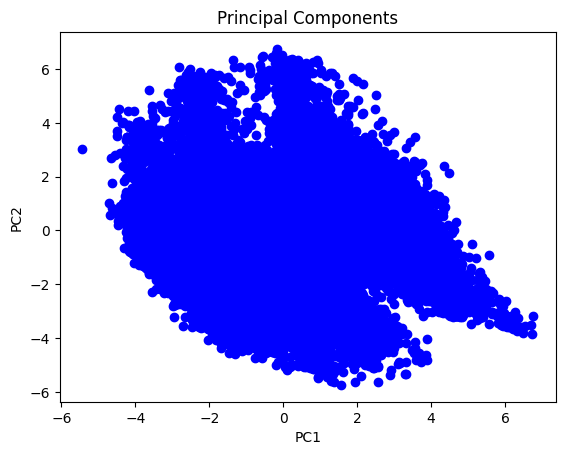

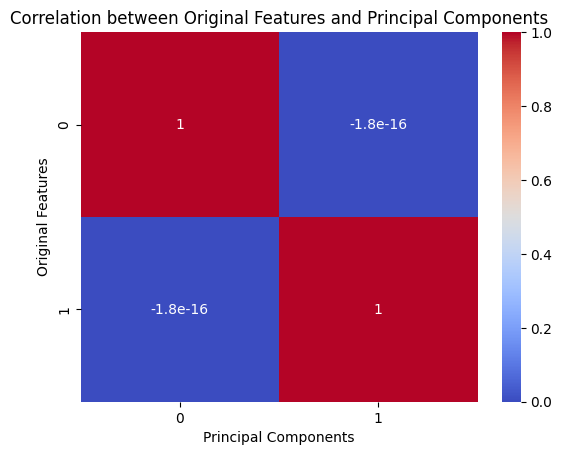

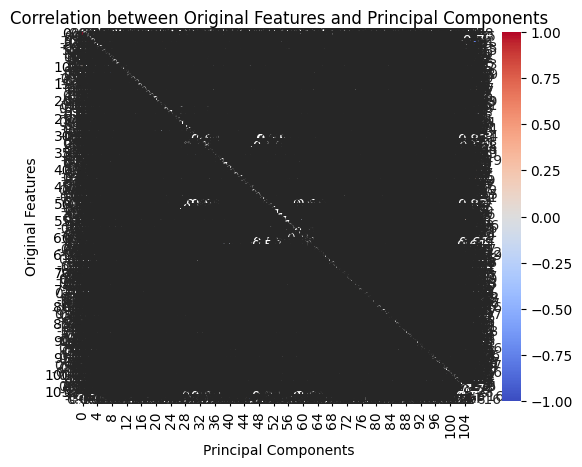

In [32]:

# Scatter Plot for 2D PCA Data (choose 2 pricipal components)
import matplotlib.pyplot as plt
# your code here:
k=2
principal_components = sorted_eigenvectors[:,:k]
pca_imp_new = np.dot(pca_imp, principal_components)


plt.scatter(pca_imp_new[:,0],pca_imp_new[:,1],c='b')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('Principal Components')
plt.show()



# Heatmap for Principal Component Correlation
# This requires calculating the correlation matrix between the original data and the PCA-transformed data.
correlation_matrix1 = np.corrcoef(pca_imp_new.T)

sns.heatmap(correlation_matrix1, annot=True, cmap='coolwarm')
plt.title('Correlation between Original Features and Principal Components')
plt.xlabel('Principal Components')
plt.ylabel('Original Features')
plt.show()

correlation_matrix2 = np.corrcoef(df_encoded.T,pca_imp_new.T)

sns.heatmap(correlation_matrix2, annot=True, cmap='coolwarm')
plt.title('Correlation between Original Features and Principal Components')
plt.xlabel('Principal Components')
plt.ylabel('Original Features')
plt.show()




